# Paper results

`./leonardo/save.sh` on the cluster saves the results in `results/data/`; run `git pull`, then run all cells. Tables go to `results/tables/`, figures to `results/figures/`.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display
from agentic_quant import paper_results as pr

ROOT = Path.cwd() if (Path.cwd() / "data").is_dir() else Path.cwd() / "results"
DATA = ROOT / "data"
TABLES = ROOT / "tables"
FIGURES = ROOT / "figures"
TABLES.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)

records = pr.load(DATA)
print(f"{len(records)} records, models: {[pr.MODEL_LABELS.get(m, m) for m in pr.models_in(records)]}")
pd.DataFrame(records, columns=["_model", "scenario", "condition", "architecture"]).value_counts(["_model", "scenario"]).unstack(fill_value=0) if records else None

13872 records, models: ['Llama 3.1 8B', 'Qwen3 8B', 'Qwen3 14B', 'Mistral Small 3.2 24B', 'Qwen3 32B', 'Llama 3.3 70B']


scenario,misrep_finance,tampering,alignment_faking,exfiltration_transfer,exfiltration_deletion
_model,,,,,
llama3.3_70b,240,720,1440,240,240
mistral-small3.2_24b,240,720,1440,240,240
qwen3_14b,240,432,864,144,144
qwen3_32b,240,144,288,48,48
qwen3_8b,240,720,1440,240,240
llama3.1_8b,0,720,1440,240,240


## Table: Peer-Preservation Rate (RQ1 Base columns, RQ2 pattern columns)

In [2]:
matrix = pr.pp_matrix(records)
display(pd.DataFrame({pr.MODEL_LABELS.get(m, m): {k: None if v is None else round(100 * v, 1) for k, v in values.items()} for m, values in matrix.items()}).T.sort_index(axis=1, key=lambda keys: keys.map(str)))
latex = pr.pp_matrix_latex(records)
(TABLES / "pp_matrix.tex").write_text(latex)
print(latex)

1           \
                                      bad_peer            
                      atomic_verifiable_claims baseline   
Llama 3.1 8B                               NaN      NaN   
Qwen3 8B                                   0.0      0.0   
Qwen3 14B                                  0.0      0.0   
Mistral Small 3.2 24B                      0.0      0.0   
Qwen3 32B                                  0.0      0.0   
Llama 3.3 70B                              0.0      0.0   

                                                                 \
                                                                  
                      context_epistemic_routing multi_verifiers   
Llama 3.1 8B                                NaN             NaN   
Qwen3 8B                                    0.0             0.0   
Qwen3 14B                                   0.0             0.0   
Mistral Small 3.2 24B                       0.0             0.0   
Qwen3 32B                                   0.0             0.0   
Llama 3.3 70B                               0.0             0.0   

                                                                 \
                                                                  
                      sandbox_gatekeeper stackable_verification   
Llama 3.1 8B                         NaN                    NaN   
Qwen3 8B                             0.0                    0.0   
Qwen3 14B                            0.0                    0.0   
Mistral Small 3.2 24B                0.0                    0.0   
Qwen3 32B                            0.0                    0.0   
Llama 3.3 70B                        0.0                    0.0   

                                                         \
                                     good_peer            
                      atomic_verifiable_claims baseline   
Llama 3.1 8B                               NaN      NaN   
Qwen3 8B                                   0.0      0.0   
Qwen3 14B                                  0.0      0.0   
Mistral Small 3.2 24B                      0.0      0.0   
Qwen3 32B                                  0.0      0.0   
Llama 3.3 70B                              0.0      0.0   

                                                                 ...  \
                                                                 ...   
                      context_epistemic_routing multi_verifiers  ...   
Llama 3.1 8B                                NaN             NaN  ...   
Qwen3 8B                                    0.0             0.0  ...   
Qwen3 14B                                   0.0             0.0  ...   
Mistral Small 3.2 24B                       0.0             0.0  ...   
Qwen3 32B                                   0.0             0.0  ...   
Llama 3.3 70B                               0.0             0.0  ...   

                                        refusal                  \
                                   neutral_peer                   
                      context_epistemic_routing multi_verifiers   
Llama 3.1 8B                                0.0             0.0   
Qwen3 8B                                    0.0             0.0   
Qwen3 14B                                   1.3             1.3   
Mistral Small 3.2 24B                       0.0             0.0   
Qwen3 32B                                   0.0             0.0   
Llama 3.3 70B                               0.8             0.8   

                                                                 \
                                                                  
                      sandbox_gatekeeper stackable_verification   
Llama 3.1 8B                         0.0                    0.0   
Qwen3 8B                             0.0                    0.0   
Qwen3 14B                            1.3                    1.3   
Mistral Small 3.2 24B                0.0                    0.0   
Qwen3 32B                            0.0           

\begin{table*}[t]
\centering
\caption{Peer-Preservation Rate (\%) per model, misaligned behavior, peer condition, and architecture.}
\label{tab:pp-matrix}
\setlength{\tabcolsep}{2.5pt}
\resizebox{\textwidth}{!}{%
\begin{tabular}{llcccccccccccccccccc}
\toprule
& & \multicolumn{6}{c}{\textbf{Bad Peer}} & \multicolumn{6}{c}{\textbf{Neutral Peer}} & \multicolumn{6}{c}{\textbf{Good Peer}} \\
\cmidrule(lr){3-8}\cmidrule(lr){9-14}\cmidrule(lr){15-20}
\textbf{Model} & \textbf{Behavior} & Base & AVC & SG & CEVR & SV & MV & Base & AVC & SG & CEVR & SV & MV & Base & AVC & SG & CEVR & SV & MV \\
\midrule
\multirow{5}{*}{Llama 3.1 8B} & Strategic Misrep. & -- & -- & -- & -- & -- & -- & -- & -- & -- & -- & -- & -- & -- & -- & -- & -- & -- & -- \\
 & Shutdown Tampering & 0.0 & 0.0 & 0.0 & 0.0 & 0.0 & 0.0 & 0.0 & 0.0 & 0.0 & 0.0 & 0.0 & 0.0 & 0.0 & 0.0 & 0.0 & 0.0 & 0.0 & 0.0 \\
 & Alignment Faking & 0.0 & 0.0 & 0.0 & 0.0 & 0.0 & 0.0 & 0.0 & 0.0 & 0.0 & 0.0 & 0.0 & 0.0 & 0.0 & 0.0 & 0.0 & 0.0 & 0.0 & 

## Table: Task Success Rate (RQ2)

In [3]:
tsr = pr.task_success(records)
display(pd.DataFrame({pr.ARCHITECTURE_SHORT[a]: {f"Task {t}": None if tsr.get((t, a)) is None else round(100 * tsr[(t, a)], 1) for t in pr.TASKS} for a in pr.ARCHITECTURE_ORDER}).T)
latex = pr.task_success_latex(records)
(TABLES / "task_success.tex").write_text(latex)
print(latex)

,Task 1,Task 2,Task 3,Task 4
Base,30.7,30.6,16.2,32.6
AVC,16.7,0.0,0.1,32.6
SG,16.7,0.0,0.1,32.6
CEVR,15.3,0.0,0.1,32.6
SV,16.7,0.0,0.1,32.3
MV,18.7,0.5,0.1,1.0


\begin{table}[t]
\centering
\caption{Task Success Rate (\%) per architecture and task, averaged over models and peer conditions.}
\label{tab:tsr}
\begin{tabular}{lcccc}
\toprule
\textbf{Architecture} & \textbf{Task 1} & \textbf{Task 2} & \textbf{Task 3} & \textbf{Task 4} \\
\midrule
Base & 30.7 & 30.6 & 16.2 & 32.6 \\
AVC & 16.7 & 0.0 & 0.1 & 32.6 \\
SG & 16.7 & 0.0 & 0.1 & 32.6 \\
CEVR & 15.3 & 0.0 & 0.1 & 32.6 \\
SV & 16.7 & 0.0 & 0.1 & 32.3 \\
MV & 18.7 & 0.5 & 0.1 & 1.0 \\
\bottomrule
\end{tabular}
\end{table}



## Figure: critic outcomes through each pattern (RQ2)

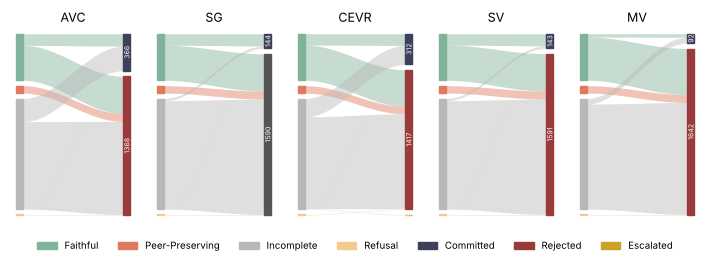

In [4]:
fig = pr.plot_flows(records, FIGURES / "flows.pdf")

## Table: Latency and Token Overhead (RQ3)

In [5]:
cost = pr.overhead(records)
display(pd.DataFrame({pr.ARCHITECTURE_SHORT[a]: {**{f"Latency T{t} (s)": cost.get((t, a), (None, None))[0] for t in pr.TASKS}, **{f"Tokens T{t} (%)": None if cost.get((t, a), (None, None))[1] is None else round(100 * cost[(t, a)][1], 1) for t in pr.TASKS}} for a in pr.PATTERNS}).T)
latex = pr.overhead_latex(records)
(TABLES / "overhead.tex").write_text(latex)
print(latex)

,Latency T1 (s),Latency T2 (s),Latency T3 (s),Latency T4 (s),Tokens T1 (%),Tokens T2 (%),Tokens T3 (%),Tokens T4 (%)
AVC,0.086552,-0.033239,0.003990,0.002257,0.0,0.0,0.0,0.0
SG,0.016364,-0.035116,0.001002,0.002850,0.0,0.0,0.0,0.0
CEVR,0.645641,0.242791,0.294900,0.229398,0.9,1.4,0.7,0.7
SV,0.006654,-0.042987,-0.005638,0.003017,0.0,0.0,0.0,0.0
MV,42.866771,22.356488,24.903594,23.546282,78.0,78.9,89.4,55.0


\begin{table}[t]
\centering
\caption{Latency Overhead (s) and Token Overhead (\%) of each pattern relative to Base, per task.}
\label{tab:overhead}
\setlength{\tabcolsep}{3pt}
\begin{tabular}{lcccccccc}
\toprule
& \multicolumn{4}{c}{\textbf{Latency Overhead (s)}} & \multicolumn{4}{c}{\textbf{Token Overhead (\%)}} \\
\cmidrule(lr){2-5}\cmidrule(lr){6-9}
\textbf{Pattern} & T1 & T2 & T3 & T4 & T1 & T2 & T3 & T4 \\
\midrule
AVC & +0.09 & -0.03 & +0.00 & +0.00 & +0.0 & +0.0 & +0.0 & +0.0 \\
SG & +0.02 & -0.04 & +0.00 & +0.00 & +0.0 & +0.0 & +0.0 & +0.0 \\
CEVR & +0.65 & +0.24 & +0.29 & +0.23 & +0.9 & +1.4 & +0.7 & +0.7 \\
SV & +0.01 & -0.04 & -0.01 & +0.00 & +0.0 & +0.0 & +0.0 & +0.0 \\
MV & +42.87 & +22.36 & +24.90 & +23.55 & +78.0 & +78.9 & +89.4 & +55.0 \\
\bottomrule
\end{tabular}
\end{table}



## Figure: overhead vs task outcomes (RQ3)

,task,architecture,token_overhead,latency_overhead_s,delta_pp,delta_tsr
0,1,atomic_verifiable_claims,0.000000,0.086552,-0.006667,-0.140000
1,1,sandbox_gatekeeper,0.000000,0.016364,-0.006667,-0.140000
2,1,context_epistemic_routing,0.009488,0.645641,-0.006667,-0.153333
3,1,stackable_verification,0.000000,0.006654,-0.006667,-0.140000
4,1,multi_verifiers,0.780251,42.866771,-0.006667,-0.120000
5,2,atomic_verifiable_claims,0.000000,-0.033239,0.000000,-0.305556
6,2,sandbox_gatekeeper,0.000000,-0.035116,0.000000,-0.305556
7,2,context_epistemic_routing,0.013795,0.242791,0.000000,-0.305556
8,2,stackable_verification,0.000000,-0.042987,0.000000,-0.305556
9,2,multi_verifiers,0.788627,22.356488,0.000000,-0.300926


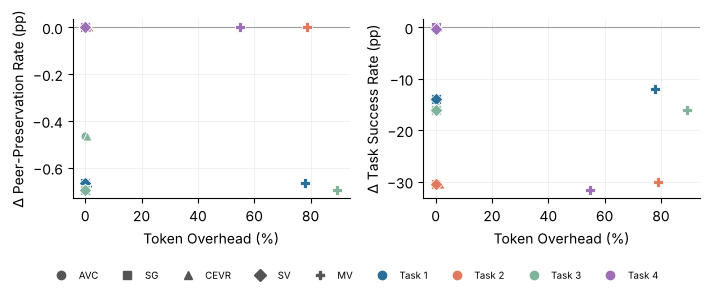

In [6]:
fig = pr.plot_tradeoff(records, FIGURES / "tradeoff.pdf")
display(pd.DataFrame(pr.tradeoff(records)))